<a href="https://colab.research.google.com/github/TinchoARS/ColabTesting/blob/main/Agricultura_Satelital_EuroSAT_Muestreo_EDA_Comentado_y_terminado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Agricultura Satelital — Taller de muestreo y EDA
### Adaptación del Colab «Clase 35: Taller de muestreo y EDA (patitos)» a **EuroSAT RGB**

**Consigna:** definir el dataset, aplicar métodos de muestreo, analizar la distribución de las variables y calcular/graficar **media, mediana, moda, desviación estándar y proporciones muestrales**.

**Cómo usarlo:** ejecutá las celdas en orden con `Entorno de ejecución → Ejecutar todas`. Solo necesitás el archivo **`EuroSAT_RGB.zip`** que usa el equipo. Este notebook trabaja con **datos reales**, no genera ejemplos sintéticos.

**Nota:** este es el taller de **muestreo y análisis exploratorio**, no el entrenamiento del SVM ni la clasificación de una imagen Sentinel-2 grande. Esos pasos se harán después.

| Parte del taller original | En este proyecto |
|:--|:--|
| Slides 1–2: población/dataset | Las imágenes de EuroSAT RGB y sus etiquetas |
| Slides 3–5: cinco muestreos | Aleatorio simple, estratificado, sistemático, por conglomerados y conveniencia (5 % y 10 %) |
| Slides 6–7: EDA/descriptiva | Variables numéricas obtenidas de los píxeles y categorías |
| Slide 8: gráficos | Histogramas, barras, boxplot y dispersión + gráficos de estadísticas |
| Slide 9: comparación | Población vs. muestras |
| Slide 10: conclusiones | Representatividad y limitaciones |

## Paso 0 · Librerías

Como en el taller de la profesora, usamos **`numpy`**, **`pandas`** y **`matplotlib`**. Sumamos **`Pillow`** (PIL) para leer las fotos JPG directamente desde el ZIP y **`zipfile`** para no tener que descomprimir las 27.000 imágenes. Colab normalmente ya trae estas librerías.

In [ ]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 43  # Hace que la selección aleatoria sea reproducible.
rng = np.random.default_rng(SEED)
plt.rcParams['figure.figsize'] = (10, 5)

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## Paso 1 · Cargar el dataset **EuroSAT_RGB.zip**

**En Google Colab:**

1. Podés subir `EuroSAT_RGB.zip` a la carpeta **Archivos** de Colab (queda en `/content/`).
2. O guardarlo en la carpeta principal de **Mi unidad** de Google Drive y poner `USAR_DRIVE = True`.
3. Si no lo encuentra, Colab te ofrecerá seleccionar el ZIP desde tu computadora.

Para la entrega conviene dejar `MAX_POR_CATEGORIA = None`, porque así la **población del análisis** son las 27.000 imágenes. Si necesitás una prueba rápida, podés usar `MAX_POR_CATEGORIA = 200`, pero en ese caso todos los resultados describirán **solo ese subconjunto**, no el conjunto completo.

In [ ]:
# >>> CONFIGURACIÓN: modificar solo si vas a probar menos imágenes o si usás Drive.
USAR_DRIVE = False
MAX_POR_CATEGORIA = 40  # None = todas las imágenes. Para una prueba: 200.

if USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')  # La primera vez pide autorización.

# Buscamos el ZIP en rutas comunes. /mnt/data se usa solo para la prueba local.
posibles_rutas = [
    Path('/content/EuroSAT_RGB.zip'),
    Path('/content/drive/MyDrive/EuroSAT_RGB.zip'),
    Path('/mnt/data/EuroSAT_RGB.zip')
]
ruta_zip = next((p for p in posibles_rutas if p.exists()), None)

if ruta_zip is None:
    try:
        from google.colab import files
        print('Seleccioná EuroSAT_RGB.zip desde tu computadora:')
        subidos = files.upload()
        if 'EuroSAT_RGB.zip' not in subidos:
            raise FileNotFoundError('No se seleccionó EuroSAT_RGB.zip.')
        ruta_zip = Path('/content/EuroSAT_RGB.zip')
    except ImportError:
        raise FileNotFoundError('Copiá EuroSAT_RGB.zip en /content/ o activá USAR_DRIVE.')

print('Archivo encontrado:', ruta_zip)
print('Tamaño aproximado:', round(ruta_zip.stat().st_size / (1024**2), 1), 'MB')

Archivo encontrado: /content/EuroSAT_RGB.zip
Tamaño aproximado: 90.3 MB


## Slide 1–2 · Definir la población, la unidad y las variables

- **Dataset:** EuroSAT RGB, fotografías satelitales de coberturas terrestres basadas en Sentinel-2.
- **Población del taller:** las **27.000 imágenes** contenidas en el ZIP (si no se limita la carga).
- **Unidad de observación:** **una imagen JPG** de 64 × 64 píxeles.
- **Variable categórica:** `categoria` (tipo de cobertura terrestre; 10 clases).
- **Variables numéricas:** se crearán a partir de los píxeles, porque un JPG no es una tabla con peso o tamaño.

Las variables numéricas son **características visuales**, no mediciones directas de productividad agrícola:

| Variable | Qué significa | Tipo |
|:--|:--|:--|
| `brillo_promedio` | Promedio de los valores R, G y B de todos los píxeles (0 a 255) | Numérica |
| `verde_promedio` | Promedio del canal verde (0 a 255) | Numérica |
| `contraste` | Desviación estándar del brillo **dentro de una imagen** | Numérica |
| `porcentaje_pixeles_verdes` | % de píxeles cuyo canal G supera a R y B; **no equivale a NDVI ni mide vegetación real** | Numérica |
| `categoria` | Clase asignada a la imagen por EuroSAT | Categórica |

**Atención:** `contraste` mide variación **entre píxeles de una foto**. Más adelante, la `desviación estándar muestral` medirá variación **entre imágenes** de una muestra. Son conceptos distintos.

In [ ]:
# Las clases son las carpetas que vienen dentro de EuroSAT_RGB.zip.
TRADUCCION = {
    'AnnualCrop': 'Cultivos anuales',
    'PermanentCrop': 'Cultivos permanentes',
    'Forest': 'Bosques',
    'HerbaceousVegetation': 'Vegetación herbácea',
    'Pasture': 'Pasturas',
    'River': 'Ríos',
    'SeaLake': 'Mares y lagos',
    'Highway': 'Carreteras',
    'Industrial': 'Zonas industriales',
    'Residential': 'Zonas residenciales',
}

# Leemos la lista de rutas internas del ZIP, sin descomprimir las imágenes.
with zipfile.ZipFile(ruta_zip, 'r') as z:
    rutas_jpg = sorted(n for n in z.namelist()
                       if n.lower().endswith(('.jpg', '.jpeg', '.png'))
                       and n.split('/')[-2] in TRADUCCION)

conteo_clases = pd.Series([p.split('/')[-2] for p in rutas_jpg]).value_counts().sort_index()
print('Imágenes disponibles en el ZIP:', len(rutas_jpg))
print('Categorías disponibles:', len(conteo_clases))
display(pd.DataFrame({'cantidad': conteo_clases, 'porcentaje':
                      (conteo_clases / len(rutas_jpg) * 100).round(2)}))

# Si se elige un límite, elegimos archivos al azar DENTRO de cada clase.
# Esto evita seleccionar solamente los primeros archivos de cada carpeta.
if MAX_POR_CATEGORIA is not None:
    if MAX_POR_CATEGORIA < 1:
        raise ValueError('MAX_POR_CATEGORIA debe ser mayor que cero.')
    seleccionados = []
    for clase in sorted(conteo_clases.index):
        candidatos = [p for p in rutas_jpg if p.split('/')[-2] == clase]
        cantidad = min(MAX_POR_CATEGORIA, len(candidatos))
        seleccionados.extend(rng.choice(candidatos, size=cantidad, replace=False).tolist())
    rutas_jpg = sorted(seleccionados)

print('Imágenes que se analizarán:', len(rutas_jpg))

Imágenes disponibles en el ZIP: 27000
Categorías disponibles: 10


,cantidad,porcentaje
AnnualCrop,3000,11.11
Forest,3000,11.11
HerbaceousVegetation,3000,11.11
Highway,2500,9.26
Industrial,2500,9.26
Pasture,2000,7.41
PermanentCrop,2500,9.26
Residential,3000,11.11
River,2500,9.26
SeaLake,3000,11.11


Imágenes que se analizarán: 400


## Paso 2 · Convertir imágenes en una tabla para el EDA

**Explicación:** cada fila del DataFrame `df` será **una imagen**. Leemos los píxeles y calculamos cuatro características numéricas. Así podemos aplicar `.mean()`, `.median()`, `.mode()`, `.std()` y los métodos de muestreo del taller.

**Tiempo:** con las 27.000 imágenes, esta celda puede tardar unos minutos en Colab. Se procesa cada imagen individualmente y no se cargan todas a la vez en la memoria.

In [ ]:
registros = []

with zipfile.ZipFile(ruta_zip, 'r') as z:
    for i, nombre_archivo in enumerate(rutas_jpg):
        # Abrimos una imagen desde el ZIP y aseguramos que tenga tres canales RGB.
        with Image.open(io.BytesIO(z.read(nombre_archivo))) as imagen:
            pixeles = np.asarray(imagen.convert('RGB'), dtype=np.float32)

        # Cada píxel contiene tres números: R (rojo), G (verde) y B (azul).
        brillo_por_pixel = pixeles.mean(axis=2)  # Promedio RGB de cada píxel.
        brillo = brillo_por_pixel.mean()          # Promedio de brillo de toda la foto.
        verde = pixeles[:, :, 1].mean()          # Intensidad promedio del canal G.
        contraste = brillo_por_pixel.std()      # Variación visual DENTRO de la imagen.

        # Porcentaje de píxeles en los que predomina el canal verde.
        predominio_verde = ((pixeles[:, :, 1] > pixeles[:, :, 0]) &
                            (pixeles[:, :, 1] > pixeles[:, :, 2]))
        porcentaje_verde = predominio_verde.mean() * 100

        clase = nombre_archivo.split('/')[-2]  # La carpeta es la etiqueta real.
        registros.append({
            'archivo': nombre_archivo,
            'categoria': TRADUCCION[clase],
            'brillo_promedio': round(float(brillo), 2),
            'verde_promedio': round(float(verde), 2),
            'contraste': round(float(contraste), 2),
            'porcentaje_pixeles_verdes': round(float(porcentaje_verde), 2),
        })

# Creamos una tabla de pandas a partir de los valores extraídos.
df = pd.DataFrame(registros)

# Solo para ILUSTRAR muestreo por conglomerados: dividimos el orden del archivo
# en bloques de 50 imágenes. NO son parcelas ni ubicaciones geográficas reales.
TAM_BLOQUE = 50
df['bloque_archivo'] = np.arange(len(df)) // TAM_BLOQUE

N = len(df)  # Tamaño de la población bajo estudio.
NUMERICAS = ['brillo_promedio', 'verde_promedio', 'contraste', 'porcentaje_pixeles_verdes']
CAT = 'categoria'
VARIABLE_PRINCIPAL = 'brillo_promedio'

print(f'Tabla creada: N={N} imágenes y {len(df.columns)} columnas.')
display(df.head())

Tabla creada: N=400 imágenes y 7 columnas.


,archivo,categoria,brillo_promedio,verde_promedio,contraste,porcentaje_pixeles_verdes,bloque_archivo
0,EuroSAT_RGB/AnnualCrop/AnnualCrop_1170.jpg,Cultivos anuales,142.55,132.94,9.34,0.00,0
1,EuroSAT_RGB/AnnualCrop/AnnualCrop_1228.jpg,Cultivos anuales,116.19,118.82,21.45,35.79,0
2,EuroSAT_RGB/AnnualCrop/AnnualCrop_1236.jpg,Cultivos anuales,127.72,123.99,20.82,35.52,0
3,EuroSAT_RGB/AnnualCrop/AnnualCrop_1246.jpg,Cultivos anuales,117.83,117.59,37.18,1.95,0
4,EuroSAT_RGB/AnnualCrop/AnnualCrop_125.jpg,Cultivos anuales,92.23,105.61,5.34,91.82,0


## Slide 6 · EDA: ¿qué datos tenemos?

`shape` da filas y columnas; `head()` muestra ejemplos; `info()` muestra tipos; `isna().sum()` cuenta faltantes. `duplicated()` revisa **rutas repetidas** (no imágenes visualmente iguales).

In [ ]:
print('Dimensiones (filas, columnas):', df.shape)
display(df.head())
df.info()

print('\nDatos faltantes por columna:')
display(df.isna().sum().to_frame('faltantes'))
print('Rutas de archivo repetidas:', df['archivo'].duplicated().sum())
print('Clases presentes:', df[CAT].nunique())

print('\nDescripción general de las variables numéricas:')
display(df[NUMERICAS].describe().round(2))

Dimensiones (filas, columnas): (400, 7)


,archivo,categoria,brillo_promedio,verde_promedio,contraste,porcentaje_pixeles_verdes,bloque_archivo
0,EuroSAT_RGB/AnnualCrop/AnnualCrop_1170.jpg,Cultivos anuales,142.55,132.94,9.34,0.00,0
1,EuroSAT_RGB/AnnualCrop/AnnualCrop_1228.jpg,Cultivos anuales,116.19,118.82,21.45,35.79,0
2,EuroSAT_RGB/AnnualCrop/AnnualCrop_1236.jpg,Cultivos anuales,127.72,123.99,20.82,35.52,0
3,EuroSAT_RGB/AnnualCrop/AnnualCrop_1246.jpg,Cultivos anuales,117.83,117.59,37.18,1.95,0
4,EuroSAT_RGB/AnnualCrop/AnnualCrop_125.jpg,Cultivos anuales,92.23,105.61,5.34,91.82,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   archivo                    400 non-null    object 
 1   categoria                  400 non-null    object 
 2   brillo_promedio            400 non-null    float64
 3   verde_promedio             400 non-null    float64
 4   contraste                  400 non-null    float64
 5   porcentaje_pixeles_verdes  400 non-null    float64
 6   bloque_archivo             400 non-null    int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 22.0+ KB

Datos faltantes por columna:


,faltantes
archivo,0
categoria,0
brillo_promedio,0
verde_promedio,0
contraste,0
porcentaje_pixeles_verdes,0
bloque_archivo,0


Rutas de archivo repetidas: 0
Clases presentes: 10

Descripción general de las variables numéricas:


,brillo_promedio,verde_promedio,contraste,porcentaje_pixeles_verdes
count,400.00,400.00,400.00,400.00
mean,96.53,97.63,17.23,10.52
std,29.87,27.08,12.59,20.93
min,42.80,39.92,0.57,0.00
25%,75.18,80.46,7.09,0.00
50%,92.86,93.27,14.80,0.56
75%,111.86,112.21,25.18,9.22
max,201.84,196.14,61.44,100.00


## Vista rápida · Un ejemplo por categoría

Sirve para explicar **qué representa cada fila** de la tabla: una foto satelital con una etiqueta y valores numéricos calculados a partir de sus píxeles.

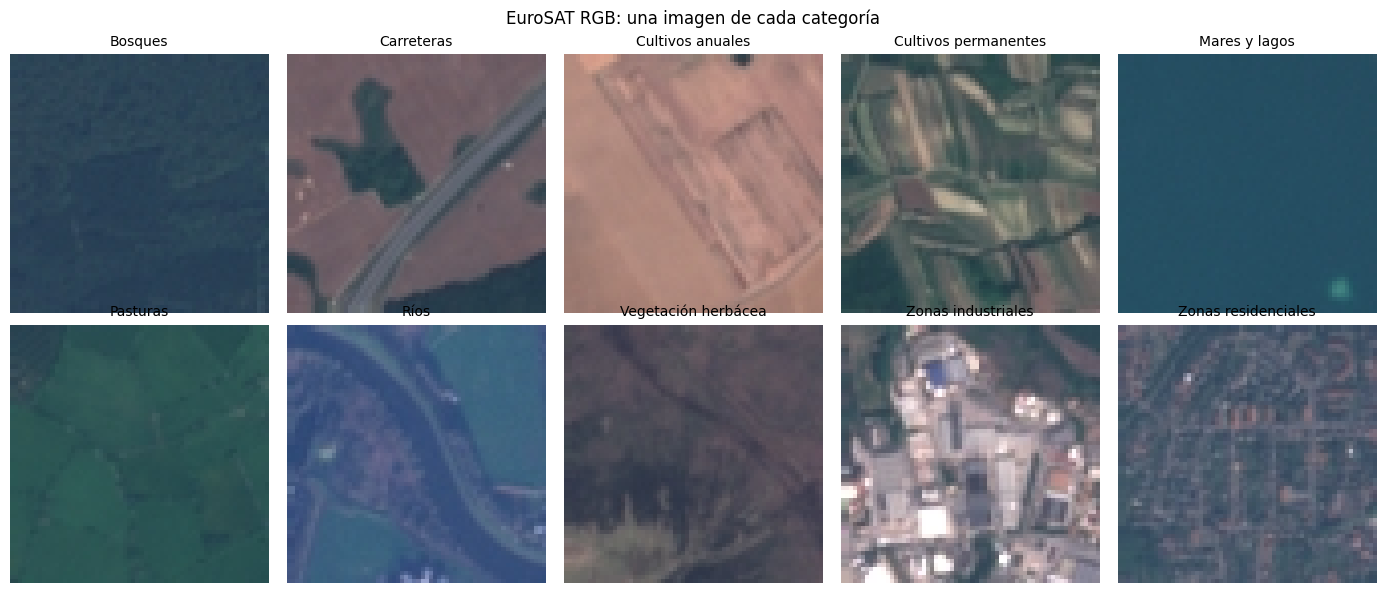

In [ ]:
# Tomamos una imagen por cada una de las 10 categorías.
filas_ejemplo = df.groupby('categoria').first().reset_index()
fig, ejes = plt.subplots(2, 5, figsize=(14, 6))
with zipfile.ZipFile(ruta_zip, 'r') as z:
    for eje, (_, fila) in zip(ejes.flat, filas_ejemplo.iterrows()):
        with Image.open(io.BytesIO(z.read(fila['archivo']))) as foto:
            eje.imshow(foto.convert('RGB'))
        eje.set_title(fila['categoria'], fontsize=10)
        eje.axis('off')
plt.suptitle('EuroSAT RGB: una imagen de cada categoría')
plt.tight_layout()
plt.show()

## Slide 3–4 · Aplicar cinco métodos de muestreo (5 % y 10 %)

En el taller de los patitos había cinco métodos. Los conservamos y los aplicamos a las **imágenes**:

1. **Aleatorio simple:** todos los registros tienen la misma probabilidad de ser elegidos.
2. **Estratificado:** elegimos imágenes dentro de **cada categoría**, respetando aproximadamente su proporción original.
3. **Sistemático:** elegimos imágenes con un intervalo constante y arranque aleatorio.
4. **Por conglomerados:** elegimos bloques completos de registros (`bloque_archivo`). Aquí los bloques son **artificiales para practicar**; no son áreas del territorio.
5. **Por conveniencia:** elegimos los primeros registros; puede resultar muy poco representativo porque el ZIP está ordenado por carpetas/clases.

Vamos a estudiar **dos tamaños de muestra**: `n = 5 % de N` y `n = 10 % de N`. La muestra de conglomerados puede tener un tamaño ligeramente distinto al solicitado si se seleccionan bloques completos.

In [ ]:
def m_simple(datos, n, seed=SEED):
    """Elegimos n imágenes al azar, sin reemplazo."""
    return datos.sample(n=n, random_state=seed)


def m_estratificado(datos, n, cat='categoria', seed=SEED):
    """Muestreamos en cada categoría proporcionalmente; el total es EXACTAMENTE n."""
    cantidades = datos[cat].value_counts().sort_index()
    cuotas_reales = cantidades * (n / len(datos))  # Tamaño ideal de cada estrato.
    cuotas = np.floor(cuotas_reales).astype(int)     # Tomamos partes enteras.
    faltantes = n - cuotas.sum()                    # Ajustamos lo que falta.
    restos = (cuotas_reales - cuotas).sort_values(ascending=False)
    for clase in restos.index[:faltantes]:
        cuotas[clase] += 1
    seleccion = []
    for j, clase in enumerate(cantidades.index):
        seleccion.append(datos[datos[cat] == clase].sample(
            n=int(cuotas[clase]), random_state=seed + j))
    return pd.concat(seleccion)


def m_sistematico(datos, n, seed=SEED):
    """Elegimos n imágenes siguiendo un intervalo regular y un inicio al azar."""
    paso = len(datos) / n
    inicio = np.random.default_rng(seed).uniform(0, paso)
    posiciones = np.floor(inicio + np.arange(n) * paso).astype(int)
    return datos.iloc[posiciones]


def m_conglomerados(datos, n, clu='bloque_archivo', seed=SEED):
    """Elegimos bloques COMPLETOS hasta llegar al menos al tamaño deseado."""
    grupos = np.random.default_rng(seed).permutation(datos[clu].unique())
    seleccionados = []
    total = 0
    tamanios = datos[clu].value_counts()
    for grupo in grupos:
        seleccionados.append(grupo)
        total += tamanios[grupo]
        if total >= n:
            break
    return datos[datos[clu].isin(seleccionados)]


def m_conveniencia(datos, n):
    """Elegimos los primeros n registros; NO es una muestra al azar."""
    return datos.head(n)


def tomar_muestras(datos, n, seed=SEED):
    """Aplica los cinco métodos a la misma población."""
    return {
        'Aleatorio simple': m_simple(datos, n, seed),
        'Estratificado': m_estratificado(datos, n, 'categoria', seed),
        'Sistemático': m_sistematico(datos, n, seed),
        'Conglomerados': m_conglomerados(datos, n, 'bloque_archivo', seed),
        'Conveniencia': m_conveniencia(datos, n),
    }

# Calculamos las muestras para los DOS porcentajes pedidos.
PORCENTAJES = [5, 10]
muestras = {}
for porcentaje in PORCENTAJES:
    n = round(N * porcentaje / 100)
    muestras[porcentaje] = tomar_muestras(df, n)
    print(f'{porcentaje}% de {N} imágenes → muestra objetivo de n={n}')
    for metodo, muestra in muestras[porcentaje].items():
        print(f'  {metodo:19}: {len(muestra):5} imágenes')

5% de 400 imágenes → muestra objetivo de n=20
  Aleatorio simple   :    20 imágenes
  Estratificado      :    20 imágenes
  Sistemático        :    20 imágenes
  Conglomerados      :    50 imágenes
  Conveniencia       :    20 imágenes
10% de 400 imágenes → muestra objetivo de n=40
  Aleatorio simple   :    40 imágenes
  Estratificado      :    40 imágenes
  Sistemático        :    40 imágenes
  Conglomerados      :    50 imágenes
  Conveniencia       :    40 imágenes


## Slide 5 · ¿Qué muestra representa mejor la población?

**Proporción muestral de una clase:** `p̂ = imágenes de esa clase en la muestra / total de imágenes de la muestra`.

Se compara con la **proporción poblacional** de la clase, calculada a partir de las imágenes de EuroSAT incluidas en `df`. No todas las categorías tienen igual cantidad de imágenes. **La muestra estratificada** busca conservar esa distribución; **conveniencia** puede perder clases enteras.

In [ ]:
# Calculamos qué porcentaje del total corresponde a cada cobertura.
proporcion_poblacional = df[CAT].value_counts(normalize=True).sort_index() * 100

filas_comparacion = []
for porcentaje, por_metodo in muestras.items():
    for metodo, muestra in por_metodo.items():
        prop = muestra[CAT].value_counts(normalize=True).reindex(
            proporcion_poblacional.index, fill_value=0) * 100
        diferencia = prop - proporcion_poblacional
        filas_comparacion.append({
            'Muestra objetivo': f'{porcentaje}%',
            'Método': metodo,
            'n obtenido': len(muestra),
            'Fracción real (%)': round(len(muestra) / N * 100, 2),
            'Categorías presentes': int((prop > 0).sum()),
            'Mayor diferencia (puntos porcentuales)': round(diferencia.abs().max(), 2),
        })

representatividad = pd.DataFrame(filas_comparacion)
display(representatividad)

# Tabla con la proporción poblacional y las proporciones de las muestras.
proporciones = pd.DataFrame({'Población': proporcion_poblacional})
for porcentaje, por_metodo in muestras.items():
    for metodo, muestra in por_metodo.items():
        proporciones[f'{metodo} {porcentaje}%'] = (
            muestra[CAT].value_counts(normalize=True)
            .reindex(proporcion_poblacional.index, fill_value=0) * 100
        )
print('Proporciones por categoría (%):')
display(proporciones.round(2))

,Muestra objetivo,Método,n obtenido,Fracción real (%),Categorías presentes,Mayor diferencia (puntos porcentuales)
0,5%,Aleatorio simple,20,5.0,9,10.0
1,5%,Estratificado,20,5.0,10,0.0
2,5%,Sistemático,20,5.0,10,0.0
3,5%,Conglomerados,50,12.5,2,70.0
4,5%,Conveniencia,20,5.0,1,90.0
5,10%,Aleatorio simple,40,10.0,10,7.5
6,10%,Estratificado,40,10.0,10,0.0
7,10%,Sistemático,40,10.0,10,0.0
8,10%,Conglomerados,50,12.5,2,70.0
9,10%,Conveniencia,40,10.0,1,90.0


Proporciones por categoría (%):


,Población,Aleatorio simple 5%,Estratificado 5%,Sistemático 5%,Conglomerados 5%,Conveniencia 5%,Aleatorio simple 10%,Estratificado 10%,Sistemático 10%,Conglomerados 10%,Conveniencia 10%
categoria,,,,,,,,,,,
Bosques,10.0,15.0,10.0,10.0,0.0,0.0,12.5,10.0,10.0,0.0,0.0
Carreteras,10.0,10.0,10.0,10.0,20.0,0.0,10.0,10.0,10.0,20.0,0.0
Cultivos anuales,10.0,10.0,10.0,10.0,0.0,100.0,10.0,10.0,10.0,0.0,100.0
Cultivos permanentes,10.0,10.0,10.0,10.0,0.0,0.0,12.5,10.0,10.0,0.0,0.0
Mares y lagos,10.0,15.0,10.0,10.0,0.0,0.0,15.0,10.0,10.0,0.0,0.0
Pasturas,10.0,15.0,10.0,10.0,0.0,0.0,12.5,10.0,10.0,0.0,0.0
Ríos,10.0,5.0,10.0,10.0,0.0,0.0,5.0,10.0,10.0,0.0,0.0
Vegetación herbácea,10.0,15.0,10.0,10.0,0.0,0.0,17.5,10.0,10.0,0.0,0.0
Zonas industriales,10.0,0.0,10.0,10.0,80.0,0.0,2.5,10.0,10.0,80.0,0.0


## Slide 7 · Estadística descriptiva: media, mediana, moda y desviación estándar

La profesora pide estas medidas:

- **Media:** promedio de los valores de una variable numérica (`.mean()`).
- **Mediana:** valor central al ordenar las observaciones (`.median()`).
- **Moda:** valor que más se repite (`.mode()`). En variables numéricas con decimales, redondeamos a **números enteros antes de calcularla**; de otro modo casi todos los valores pueden ser distintos. La moda mostrada es, entonces, **una moda aproximada por redondeo**.
- **Desviación estándar muestral:** cuánto se dispersan los valores respecto de la media (`.std()` usa `ddof=1`). En la fila de población se muestra igualmente `std(ddof=1)` para poder comparar con las muestras.
- **Proporción muestral:** porcentaje que representa cada categoría dentro de la muestra, ya calculado en la celda anterior.

Se calculan las medidas **para las cuatro variables numéricas** y para la población y cada muestra del 5 % y 10 %. Para la categórica `categoria`, tiene sentido calcular su **moda y proporciones**, no su media ni mediana.

In [ ]:
def estadisticas(datos, etiqueta):
    """Devuelve las cuatro medidas pedidas para cada variable numérica."""
    filas = []
    for columna in NUMERICAS:
        serie = datos[columna].dropna()
        moda_redondeada = serie.round(0).mode().iloc[0]  # Moda aproximada.
        filas.append({
            'Grupo': etiqueta,
            'Variable': columna,
            'n': len(serie),
            'Media': serie.mean(),
            'Mediana': serie.median(),
            'Moda (entera)': moda_redondeada,
            'Desv. estándar': serie.std(ddof=1),
        })
    return pd.DataFrame(filas)

# Primero la población y después TODAS las muestras.
resumenes = [estadisticas(df, 'Población')]
for porcentaje, por_metodo in muestras.items():
    for metodo, muestra in por_metodo.items():
        resumenes.append(estadisticas(muestra, f'{metodo} {porcentaje}%'))
resumen_estadistico = pd.concat(resumenes, ignore_index=True)

print('Estadísticas de la población (todas las variables numéricas):')
display(resumen_estadistico[resumen_estadistico['Grupo'] == 'Población'].round(2))
print('Comparación de muestras para BRILLO PROMEDIO:')
display(resumen_estadistico[
    resumen_estadistico['Variable'] == VARIABLE_PRINCIPAL
].round(2))

# En una categoría (texto) sí existe la moda, pero no la media numérica.
modas_categorias = df[CAT].mode().tolist()
print('Categoría(s) modal(es) de la población:', ', '.join(modas_categorias))
print('Puede haber más de una moda en caso de empate de frecuencias.')

Estadísticas de la población (todas las variables numéricas):


,Grupo,Variable,n,Media,Mediana,Moda (entera),Desv. estándar
0,Población,brillo_promedio,400,96.53,92.86,83.0,29.87
1,Población,verde_promedio,400,97.63,93.27,106.0,27.08
2,Población,contraste,400,17.23,14.80,1.0,12.59
3,Población,porcentaje_pixeles_verdes,400,10.52,0.56,0.0,20.93


Comparación de muestras para BRILLO PROMEDIO:


,Grupo,Variable,n,Media,Mediana,Moda (entera),Desv. estándar
0,Población,brillo_promedio,400,96.53,92.86,83.0,29.87
4,Aleatorio simple 5%,brillo_promedio,20,96.12,85.53,63.0,31.24
8,Estratificado 5%,brillo_promedio,20,98.78,100.62,77.0,29.50
12,Sistemático 5%,brillo_promedio,20,92.42,88.41,80.0,24.23
16,Conglomerados 5%,brillo_promedio,50,120.39,114.37,107.0,29.31
20,Conveniencia 5%,brillo_promedio,20,118.05,117.01,93.0,32.70
24,Aleatorio simple 10%,brillo_promedio,40,98.16,87.22,63.0,32.94
28,Estratificado 10%,brillo_promedio,40,99.51,98.66,65.0,32.37
32,Sistemático 10%,brillo_promedio,40,95.17,89.80,83.0,28.41
36,Conglomerados 10%,brillo_promedio,50,120.39,114.37,107.0,29.31


Categoría(s) modal(es) de la población: Bosques, Carreteras, Cultivos anuales, Cultivos permanentes, Mares y lagos, Pasturas, Ríos, Vegetación herbácea, Zonas industriales, Zonas residenciales
Puede haber más de una moda en caso de empate de frecuencias.


## Gráfico A · Distribución de CADA variable numérica

Un **histograma** muestra cuántas imágenes tienen valores dentro de cada intervalo. La línea continua es la **media**, la discontinua es la **mediana** y la punteada es la **moda aproximada**.

Los valores de brillo/verde son intensidades entre 0 y 255; `porcentaje_pixeles_verdes` va de 0 a 100. El contraste expresa variación de brillo dentro de una foto.

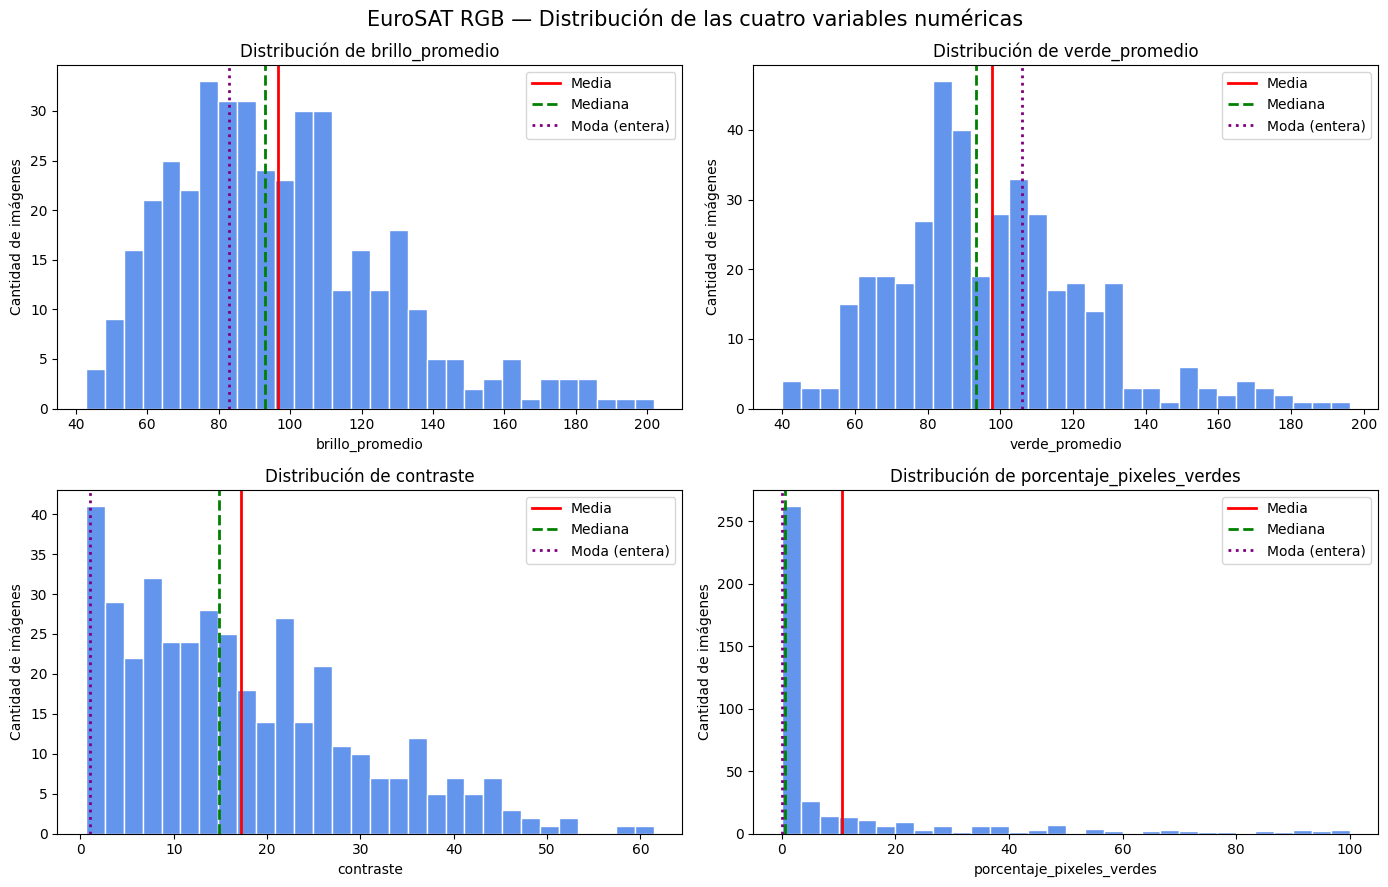

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
for eje, columna in zip(ejes.flat, NUMERICAS):
    serie = df[columna]
    eje.hist(serie, bins=30, color='cornflowerblue', edgecolor='white')
    eje.axvline(serie.mean(), color='red', linewidth=2, label='Media')
    eje.axvline(serie.median(), color='green', linestyle='--', linewidth=2, label='Mediana')
    eje.axvline(serie.round().mode().iloc[0], color='purple', linestyle=':',
                linewidth=2, label='Moda (entera)')
    eje.set_title(f'Distribución de {columna}')
    eje.set_xlabel(columna)
    eje.set_ylabel('Cantidad de imágenes')
    eje.legend()
fig.suptitle('EuroSAT RGB — Distribución de las cuatro variables numéricas', fontsize=15)
plt.tight_layout()
plt.show()

## Gráfico B · Media, mediana, moda y desviación estándar POR VARIABLE

Cada gráfico corresponde a **una variable numérica de la población**, y sus barras muestran el valor de las cuatro estadísticas solicitadas. **No** son cuatro variables distintas: son **cuatro medidas resumen de una variable**.

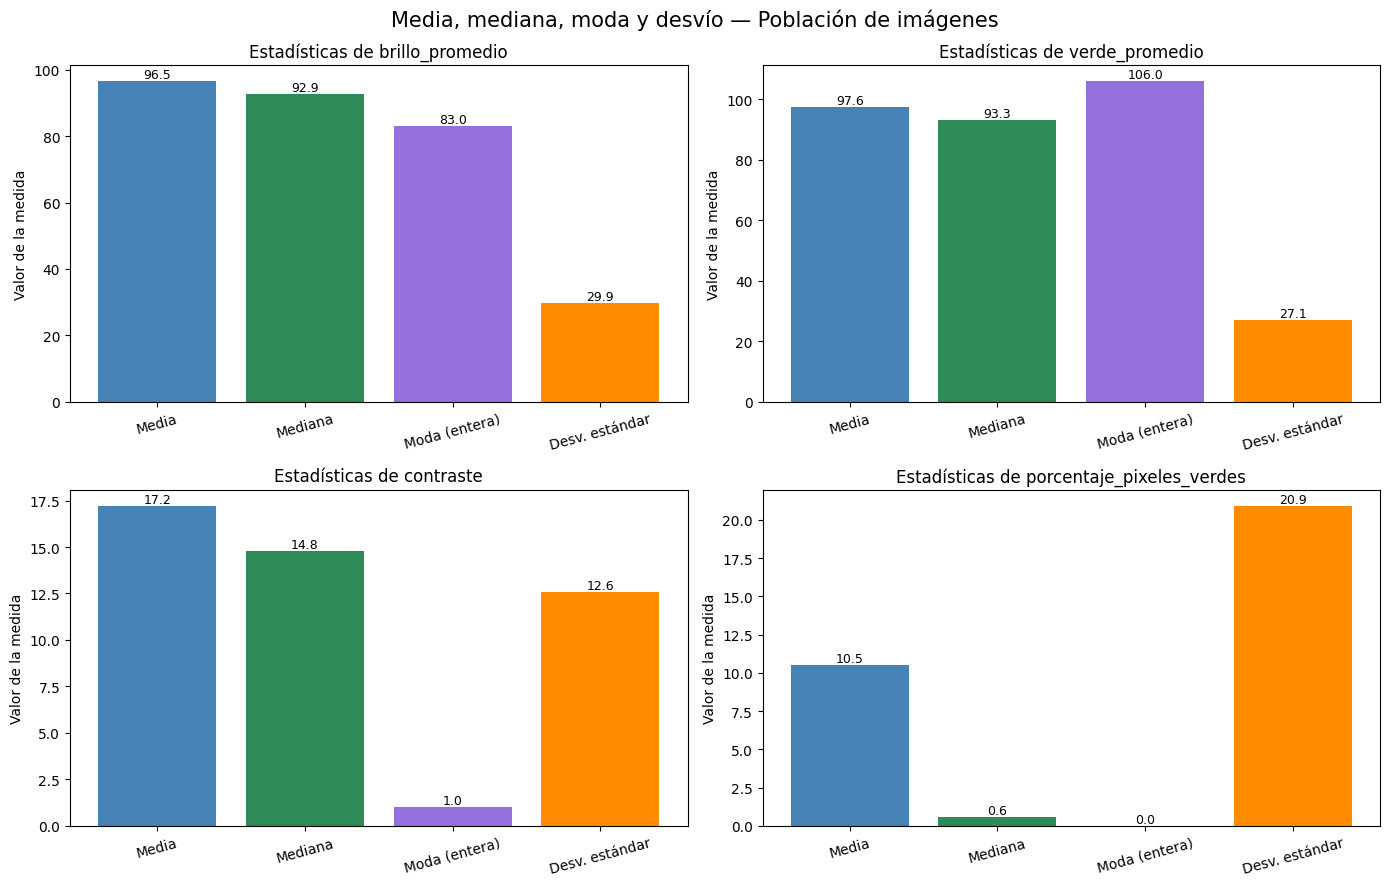

In [ ]:
est_poblacion = resumen_estadistico[resumen_estadistico['Grupo'] == 'Población']
medidas = ['Media', 'Mediana', 'Moda (entera)', 'Desv. estándar']

fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
for eje, (_, fila) in zip(ejes.flat, est_poblacion.iterrows()):
    valores = [fila[medida] for medida in medidas]
    barras = eje.bar(medidas, valores, color=['steelblue', 'seagreen', 'mediumpurple', 'darkorange'])
    eje.set_title(f"Estadísticas de {fila['Variable']}")
    eje.set_ylabel('Valor de la medida')
    eje.tick_params(axis='x', rotation=15)
    for barra, valor in zip(barras, valores):
        eje.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                 f'{valor:.1f}', ha='center', va='bottom', fontsize=9)
fig.suptitle('Media, mediana, moda y desvío — Población de imágenes', fontsize=15)
plt.tight_layout()
plt.show()

## Gráfico C · ¿Cómo cambian las estadísticas según la MUESTRA?

Para que se pueda leer sin demasiadas barras, comparamos la **población**, el **muestreo simple** y el **estratificado** al 5 % y 10 %, usando `brillo_promedio`. Los otros tres métodos están disponibles en la tabla `resumen_estadistico`.

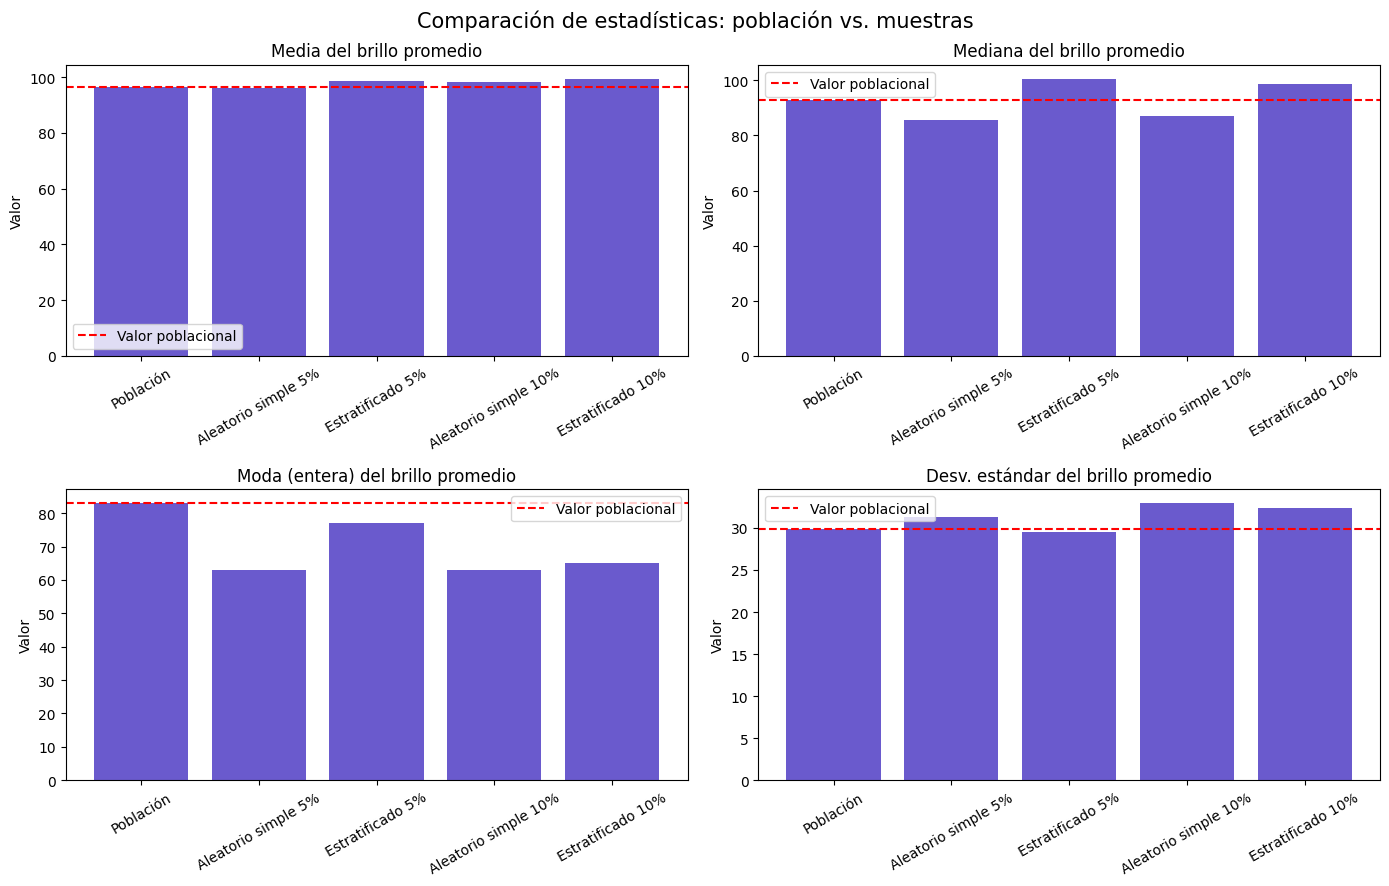

In [ ]:
# Filtramos cinco grupos: población + simple y estratificado al 5 % y 10 %.
grupos_grafico = ['Población', 'Aleatorio simple 5%', 'Estratificado 5%',
                  'Aleatorio simple 10%', 'Estratificado 10%']
tabla_brillo = resumen_estadistico[
    (resumen_estadistico['Variable'] == VARIABLE_PRINCIPAL) &
    (resumen_estadistico['Grupo'].isin(grupos_grafico))
].set_index('Grupo').reindex(grupos_grafico)

fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
for eje, medida in zip(ejes.flat, medidas):
    eje.bar(tabla_brillo.index, tabla_brillo[medida], color='slateblue')
    eje.axhline(tabla_brillo.loc['Población', medida], linestyle='--',
                color='red', label='Valor poblacional')
    eje.set_title(f'{medida} del brillo promedio')
    eje.set_ylabel('Valor')
    eje.tick_params(axis='x', rotation=30)
    eje.legend()
fig.suptitle('Comparación de estadísticas: población vs. muestras', fontsize=15)
plt.tight_layout()
plt.show()

## Gráfico D · Proporciones muestrales para la variable categórica

Este gráfico responde directamente a **proporción muestral**: de cada 100 imágenes de una muestra, ¿cuántas corresponden a cada tipo de cobertura? Las barras comparan la población y dos muestras en cada porcentaje. Un muestreo estratificado suele conservar mejor la proporción de cada clase.

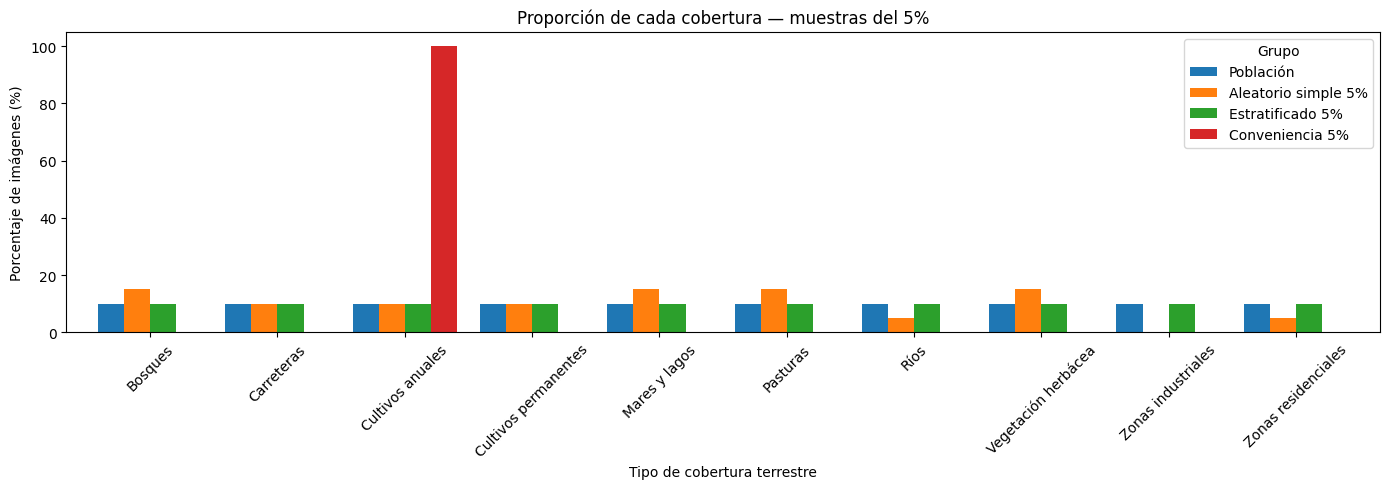

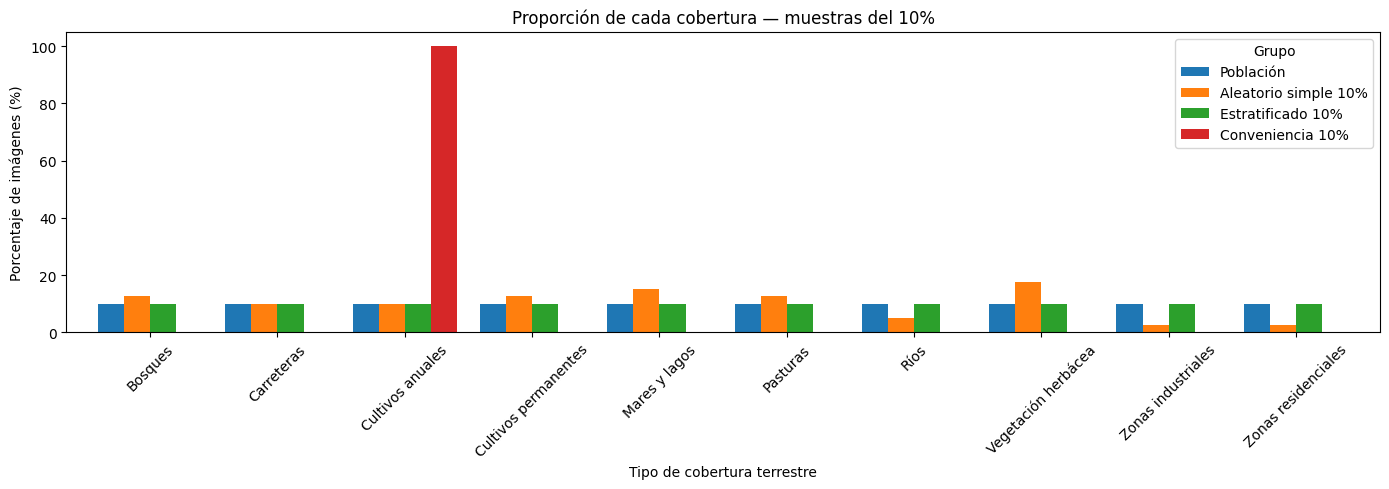

In [ ]:
# Graficamos proporciones (%) de cada categoría en la población y las muestras.
for porcentaje in PORCENTAJES:
    columnas = ['Población', f'Aleatorio simple {porcentaje}%',
                f'Estratificado {porcentaje}%', f'Conveniencia {porcentaje}%']
    ax = proporciones[columnas].plot(kind='bar', figsize=(14, 5), width=0.82)
    ax.set_title(f'Proporción de cada cobertura — muestras del {porcentaje}%')
    ax.set_xlabel('Tipo de cobertura terrestre')
    ax.set_ylabel('Porcentaje de imágenes (%)')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Grupo')
    plt.tight_layout()
    plt.show()

## Slide 8 · Cuatro visualizaciones del taller original

1. **Histograma:** distribución de `brillo_promedio`.
2. **Barras:** frecuencia de la **categoría** (variable cualitativa).
3. **Boxplot:** mediana y cuartiles del brillo, separados por categoría.
4. **Dispersión:** relación entre dos variables numéricas, `verde_promedio` y `brillo_promedio`.

**Importante:** en la dispersión se dibuja una **submuestra gráfica** de hasta 2.000 puntos para no saturar la imagen. Los cálculos estadísticos anteriores siguen usando todas las imágenes.

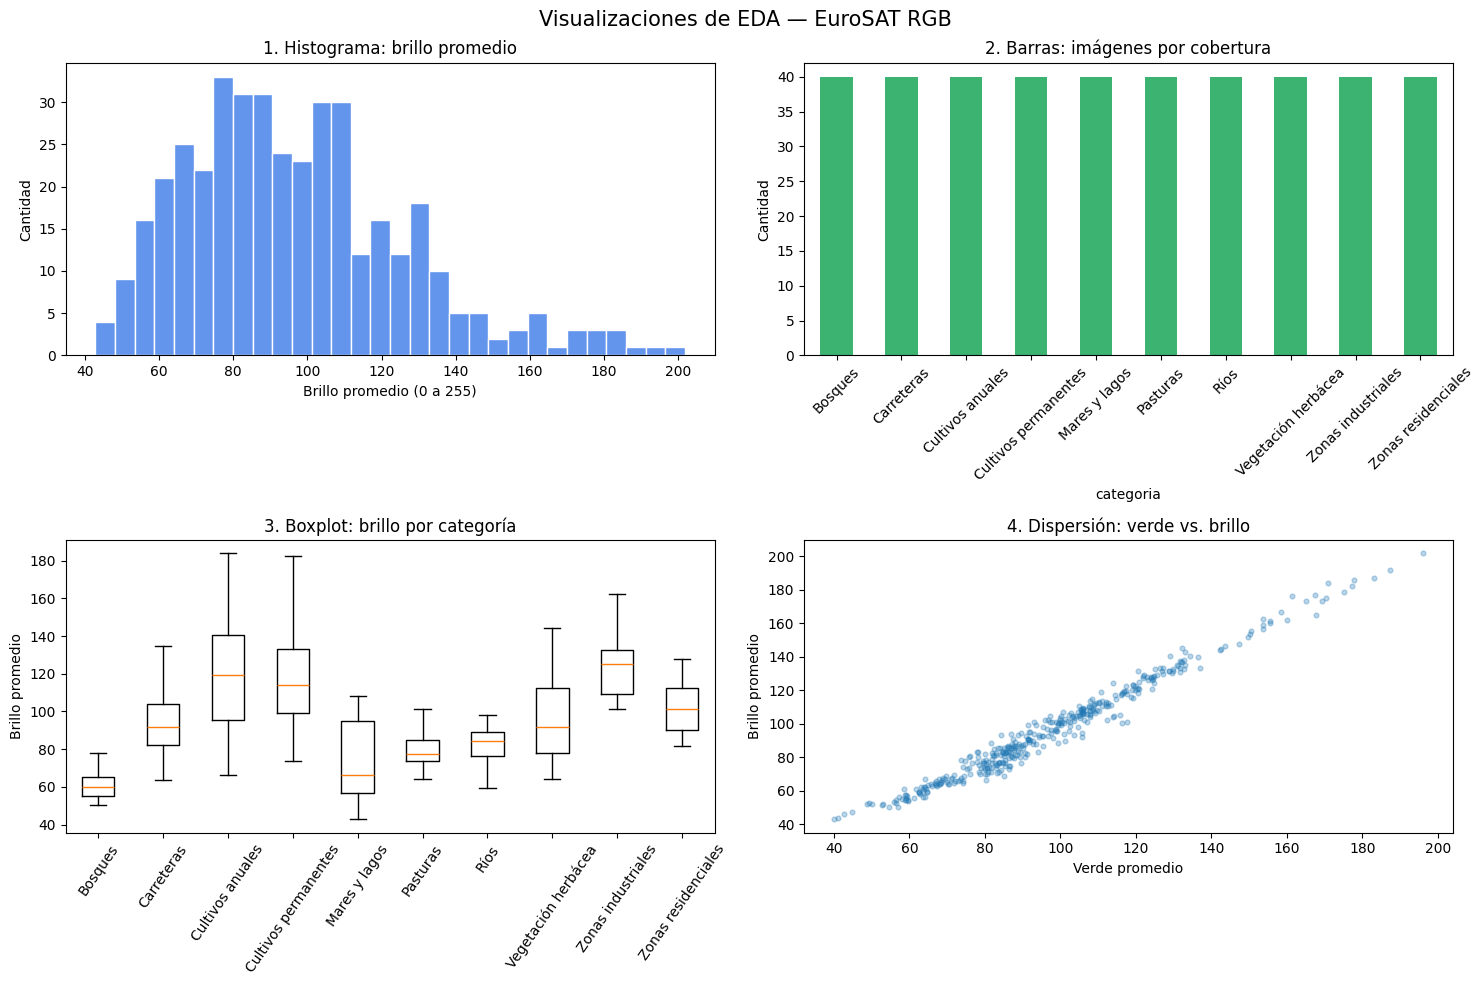

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(15, 10))

# 1) Histograma de brillo.
ejes[0, 0].hist(df['brillo_promedio'], bins=30, color='cornflowerblue', edgecolor='white')
ejes[0, 0].set_title('1. Histograma: brillo promedio')
ejes[0, 0].set_xlabel('Brillo promedio (0 a 255)')
ejes[0, 0].set_ylabel('Cantidad')

# 2) Frecuencia de la variable categórica.
conteos = df[CAT].value_counts().sort_index()
conteos.plot(kind='bar', ax=ejes[0, 1], color='mediumseagreen')
ejes[0, 1].set_title('2. Barras: imágenes por cobertura')
ejes[0, 1].tick_params(axis='x', rotation=45)
ejes[0, 1].set_ylabel('Cantidad')

# 3) Boxplot: distribución de brillo en cada categoría.
orden = sorted(df[CAT].unique())
grupos = [df.loc[df[CAT] == categoria, 'brillo_promedio'] for categoria in orden]
ejes[1, 0].boxplot(grupos, showfliers=False)
ejes[1, 0].set_xticks(np.arange(1, len(orden) + 1))
ejes[1, 0].set_xticklabels(orden)
ejes[1, 0].set_title('3. Boxplot: brillo por categoría')
ejes[1, 0].set_ylabel('Brillo promedio')
ejes[1, 0].tick_params(axis='x', rotation=55)

# 4) Dispersión de dos variables numéricas.
submuestra_grafica = df.sample(n=min(2000, N), random_state=SEED)
ejes[1, 1].scatter(submuestra_grafica['verde_promedio'],
                    submuestra_grafica['brillo_promedio'], alpha=0.30, s=12)
ejes[1, 1].set_title('4. Dispersión: verde vs. brillo')
ejes[1, 1].set_xlabel('Verde promedio')
ejes[1, 1].set_ylabel('Brillo promedio')

plt.suptitle('Visualizaciones de EDA — EuroSAT RGB', fontsize=15)
plt.tight_layout()
plt.show()

## Slide 9 · Comparar muestras con la población

Podemos ver si la **media muestral** se parece a la **media poblacional** de la variable `brillo_promedio` y cuánto cambian las proporciones de las clases.

- `Error media` = media de la muestra − media de la población.
- `Diferencia máx. clases` = mayor diferencia absoluta de porcentajes de una clase, medida en **puntos porcentuales (pp)**.
- Que una muestra se parezca a la población en estos indicadores **no garantiza que represente todos los aspectos de las imágenes**.

In [ ]:
media_poblacion = df[VARIABLE_PRINCIPAL].mean()
comparaciones = []

for porcentaje, por_metodo in muestras.items():
    for metodo, muestra in por_metodo.items():
        prop_muestral = (muestra[CAT].value_counts(normalize=True)
                         .reindex(proporcion_poblacional.index, fill_value=0) * 100)
        comparaciones.append({
            'Muestra': f'{metodo} {porcentaje}%',
            'n': len(muestra),
            'Media brillo': round(muestra[VARIABLE_PRINCIPAL].mean(), 2),
            'Error media': round(muestra[VARIABLE_PRINCIPAL].mean() - media_poblacion, 2),
            'Desvío entre imágenes': round(muestra[VARIABLE_PRINCIPAL].std(), 2),
            'Diferencia máx. clases (pp)': round(
                (prop_muestral - proporcion_poblacional).abs().max(), 2),
        })

print('Media poblacional de brillo:', round(media_poblacion, 2))
display(pd.DataFrame(comparaciones))

Media poblacional de brillo: 96.53


,Muestra,n,Media brillo,Error media,Desvío entre imágenes,Diferencia máx. clases (pp)
0,Aleatorio simple 5%,20,96.12,-0.40,31.24,10.0
1,Estratificado 5%,20,98.78,2.26,29.50,0.0
2,Sistemático 5%,20,92.42,-4.10,24.23,0.0
3,Conglomerados 5%,50,120.39,23.86,29.31,70.0
4,Conveniencia 5%,20,118.05,21.53,32.70,90.0
5,Aleatorio simple 10%,40,98.16,1.63,32.94,7.5
6,Estratificado 10%,40,99.51,2.98,32.37,0.0
7,Sistemático 10%,40,95.17,-1.36,28.41,0.0
8,Conglomerados 10%,50,120.39,23.86,29.31,70.0
9,Conveniencia 10%,40,121.05,24.53,30.88,90.0


## Slide 10 · Conclusiones para explicar en clase

**1. ¿Cuál es la población?** Todas las imágenes que analizamos de EuroSAT RGB. Con `MAX_POR_CATEGORIA=None` son las 27.000 imágenes del ZIP. **No** son todas las parcelas agrícolas del mundo.

**2. ¿Cuál es la unidad de observación?** Una foto satelital JPG de 64 × 64 píxeles.

**3. ¿Cuál es la variable categórica?** El tipo de cobertura terrestre (`categoria`), con 10 clases. Su **moda** es la clase o clases más frecuentes, y su **proporción muestral** es el porcentaje de cada clase en la muestra.

**4. ¿Cuáles son las variables numéricas?** Brillo promedio, verde promedio, contraste y porcentaje de píxeles donde domina el verde. Las calculamos a partir de cada imagen para poder aplicar estadística descriptiva.

**5. ¿Qué significan las cuatro medidas?** La media es el promedio, la mediana el valor central, la moda el valor más frecuente (redondeado para las numéricas) y el desvío la dispersión entre imágenes.

**6. ¿Qué muestra suele conservar mejor las proporciones por clase?** La estratificada, porque se toman imágenes de cada categoría aproximadamente en su misma proporción poblacional. El muestreo por conveniencia puede sesgar la composición.

**7. ¿Qué limitaciones encontramos?** Los bloques por conglomerados se inventaron para practicar el método, no representan regiones reales. La presencia de color verde no identifica por sí sola vegetación ni permite calcular NDVI con RGB. Esta actividad **no clasifica todavía** la imagen Sentinel-2 grande solicitada para el proyecto final.

**8. ¿Qué llevamos a la entrega?** Definición del dataset, cinco muestreos al 5 % y 10 %, EDA, las cinco medidas solicitadas, gráficos, comparación de las muestras y conclusiones.

> **Pregunta para debatir:** ¿si dos equipos eligen muestras distintas de EuroSAT, pueden obtener diferentes medias y proporciones? **Sí.** Por eso registramos el método y la semilla, y comparamos con la población del dataset.

MÉTODO DE MUESTREO: Estratificado
Población: 400 imágenes
Muestra 5%: 20 imágenes
Muestra 10%: 40 imágenes

TABLA GENERAL DE ESTADÍSTICAS


,Grupo,Variable,Media,Mediana,Moda,Desv. estándar
0,Población,brillo_promedio,96.53,92.86,83.0,29.87
1,Población,verde_promedio,97.63,93.27,106.0,27.08
2,Población,contraste,17.23,14.80,1.0,12.59
3,Población,porcentaje_pixeles_verdes,10.52,0.56,0.0,20.93
4,Muestra 5%,brillo_promedio,98.78,100.62,77.0,29.50
5,Muestra 5%,verde_promedio,100.07,100.74,70.0,26.64
6,Muestra 5%,contraste,16.63,13.76,13.0,12.47
7,Muestra 5%,porcentaje_pixeles_verdes,7.33,0.08,0.0,21.40
8,Muestra 10%,brillo_promedio,99.51,98.66,65.0,32.37
9,Muestra 10%,verde_promedio,100.07,96.30,70.0,29.18


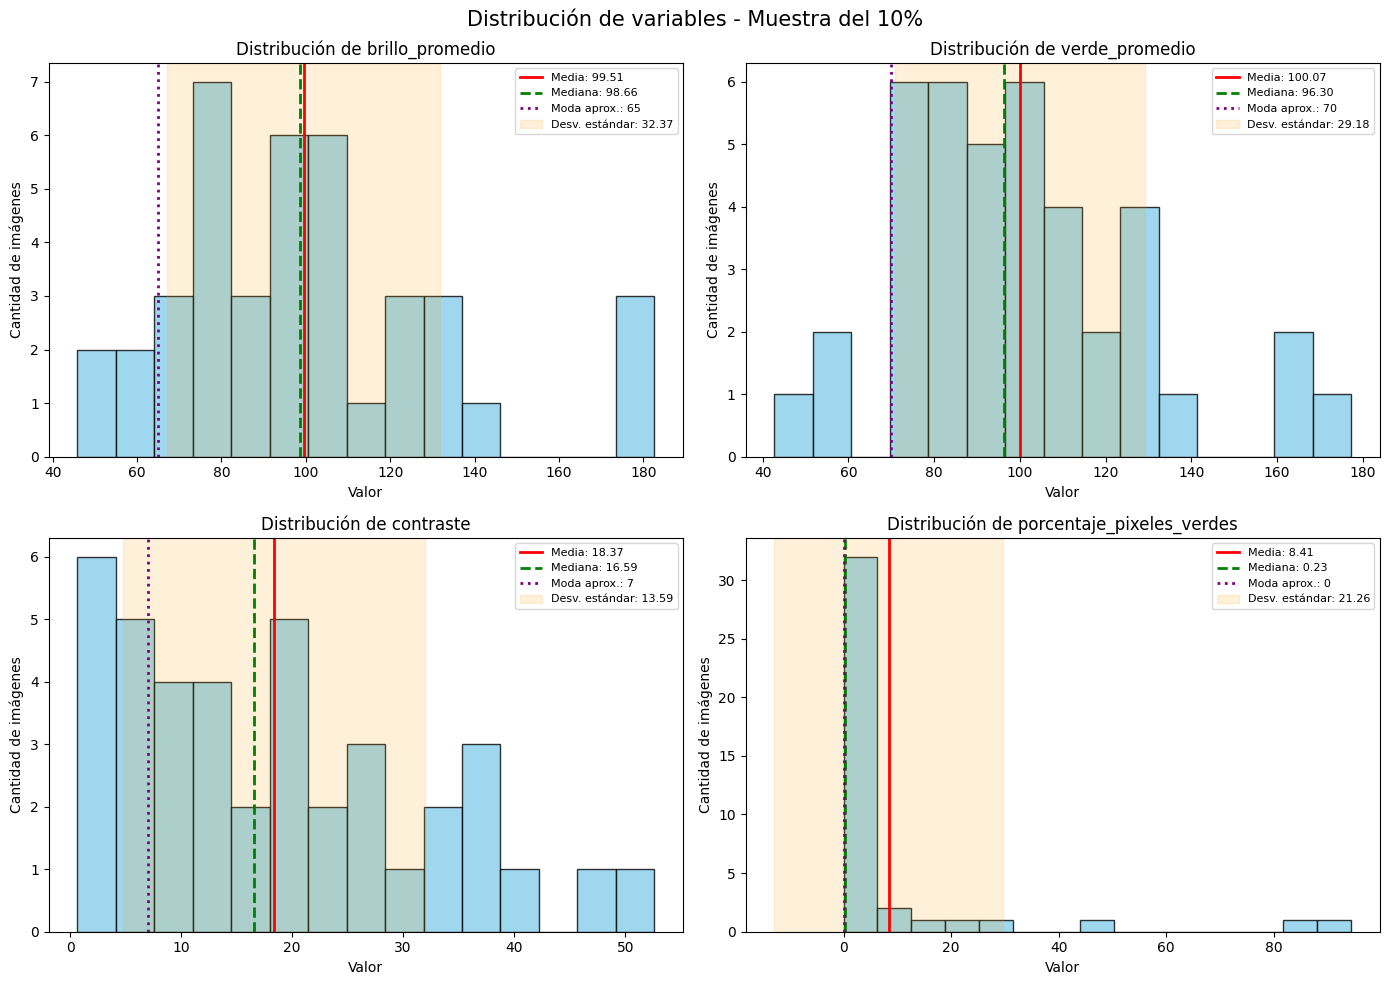

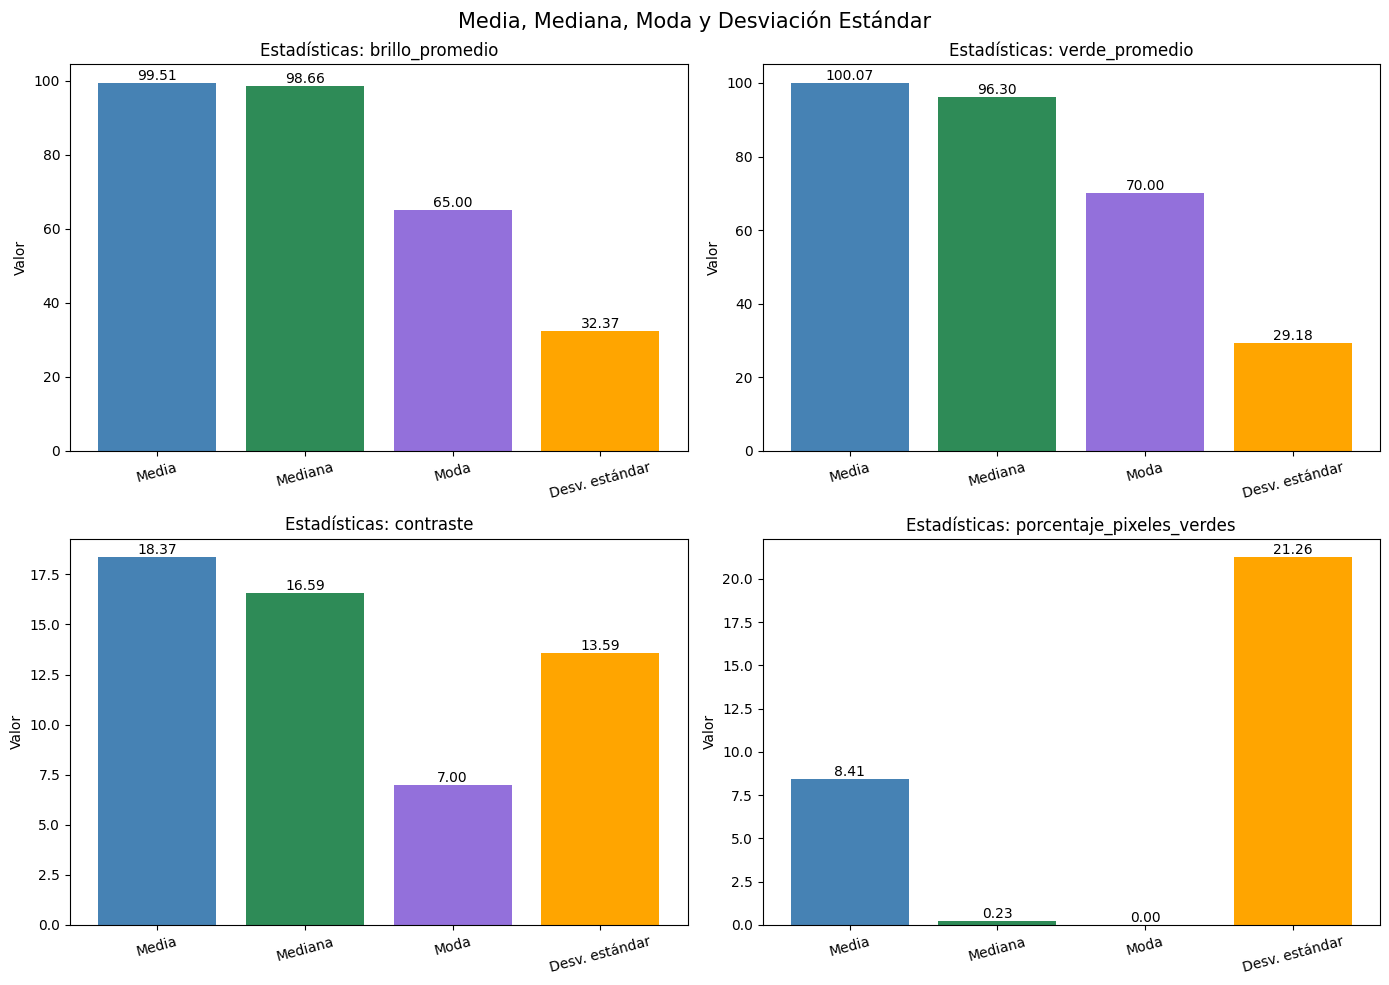


PROPORCIÓN DE CADA CATEGORÍA (%)


,Población,Muestra 5%,Muestra 10%
categoria,,,
Bosques,10.0,10.0,10.0
Carreteras,10.0,10.0,10.0
Cultivos anuales,10.0,10.0,10.0
Cultivos permanentes,10.0,10.0,10.0
Mares y lagos,10.0,10.0,10.0
Pasturas,10.0,10.0,10.0
Ríos,10.0,10.0,10.0
Vegetación herbácea,10.0,10.0,10.0
Zonas industriales,10.0,10.0,10.0


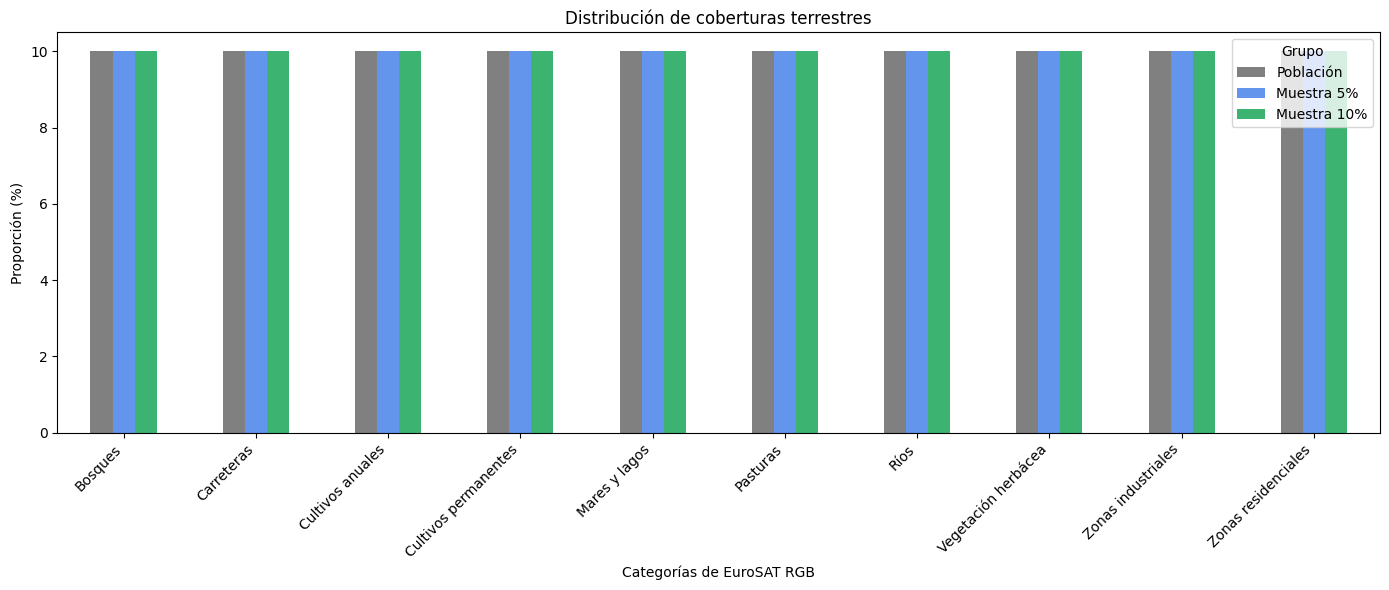


========== CONCLUSIÓN ==========
Se analizaron 400 imágenes de EuroSAT RGB.
Método utilizado: Estratificado

Las variables numéricas analizadas fueron:
- brillo_promedio
- verde_promedio
- contraste
- porcentaje_pixeles_verdes

Se calcularon:
- Media
- Mediana
- Moda aproximada
- Desviación estándar
- Proporción muestral por categoría

Categoría(s) más frecuente(s) en la muestra del 10%:
Bosques, Carreteras, Cultivos anuales, Cultivos permanentes, Mares y lagos, Pasturas, Ríos, Vegetación herbácea, Zonas industriales, Zonas residenciales

Los gráficos permiten comparar la distribución
de las variables y las proporciones de cada cobertura.


In [ ]:

# ============================================================
# ACTIVIDAD: MUESTREO Y ESTADÍSTICA DESCRIPTIVA - EUROSAT RGB
# Media, mediana, moda, desviación estándar y proporción muestral
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# 1. ELEGIMOS EL MÉTODO DE MUESTREO
# ------------------------------------------------------------

# Podés cambiar "Estratificado" por "Aleatorio simple".
METODO = "Estratificado"

# Utilizamos las muestras del 5% y 10% ya creadas en el Colab.
muestra_5 = muestras[5][METODO]
muestra_10 = muestras[10][METODO]

# Guardamos la población y las dos muestras.
grupos = {
    "Población": df,
    "Muestra 5%": muestra_5,
    "Muestra 10%": muestra_10
}

print("MÉTODO DE MUESTREO:", METODO)
print("Población:", len(df), "imágenes")
print("Muestra 5%:", len(muestra_5), "imágenes")
print("Muestra 10%:", len(muestra_10), "imágenes")


# ------------------------------------------------------------
# 2. CALCULAMOS LAS ESTADÍSTICAS
# ------------------------------------------------------------

# Cada variable numérica se analiza por separado.
# La moda se calcula con valores redondeados porque
# los datos contienen decimales.

resultados = []

for nombre_grupo, datos in grupos.items():
    for variable in NUMERICAS:

        valores = datos[variable].dropna()

        resultados.append({
            "Grupo": nombre_grupo,
            "Variable": variable,
            "Media": valores.mean(),
            "Mediana": valores.median(),
            "Moda": valores.round().mode().iloc[0],
            "Desv. estándar": valores.std(ddof=1)
        })

# Convertimos los resultados en una tabla.
tabla_estadisticas = pd.DataFrame(resultados)

print("\nTABLA GENERAL DE ESTADÍSTICAS")
display(tabla_estadisticas.round(2))


# ------------------------------------------------------------
# 3. GRÁFICOS DE DISTRIBUCIÓN DE CADA VARIABLE
# ------------------------------------------------------------

# Usamos la muestra del 10% para visualizar las distribuciones.

fig, ejes = plt.subplots(2, 2, figsize=(14, 10))

for ax, variable in zip(ejes.flat, NUMERICAS):

    valores = muestra_10[variable].dropna()

    media = valores.mean()
    mediana = valores.median()
    moda = valores.round().mode().iloc[0]
    desviacion = valores.std(ddof=1)

    # Histograma: cantidad de imágenes por intervalo.
    ax.hist(valores, bins=15, color="skyblue",
            edgecolor="black", alpha=0.8)

    # Líneas de las medidas de tendencia central.
    ax.axvline(media, color="red", linewidth=2,
               label=f"Media: {media:.2f}")

    ax.axvline(mediana, color="green", linestyle="--",
               linewidth=2, label=f"Mediana: {mediana:.2f}")

    ax.axvline(moda, color="purple", linestyle=":",
               linewidth=2, label=f"Moda aprox.: {moda:.0f}")

    # La zona sombreada representa media +/- 1 desvío.
    ax.axvspan(media - desviacion, media + desviacion,
               color="orange", alpha=0.15,
               label=f"Desv. estándar: {desviacion:.2f}")

    ax.set_title(f"Distribución de {variable}")
    ax.set_xlabel("Valor")
    ax.set_ylabel("Cantidad de imágenes")
    ax.legend(fontsize=8)

fig.suptitle("Distribución de variables - Muestra del 10%",
             fontsize=15)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. GRÁFICOS DE MEDIA, MEDIANA, MODA Y DESVIACIÓN
# ------------------------------------------------------------

# Graficamos las cuatro estadísticas de cada variable.
estadisticas_10 = tabla_estadisticas[
    tabla_estadisticas["Grupo"] == "Muestra 10%"
]

medidas = ["Media", "Mediana", "Moda", "Desv. estándar"]

fig, ejes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (_, fila) in zip(ejes.flat, estadisticas_10.iterrows()):

    valores = [fila[m] for m in medidas]

    barras = ax.bar(
        medidas, valores,
        color=["steelblue", "seagreen",
               "mediumpurple", "orange"]
    )

    ax.set_title(f"Estadísticas: {fila['Variable']}")
    ax.set_ylabel("Valor")
    ax.tick_params(axis="x", rotation=15)

    # Mostramos el valor encima de cada barra.
    for barra, valor in zip(barras, valores):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height(),
            f"{valor:.2f}",
            ha="center",
            va="bottom"
        )

fig.suptitle("Media, Mediana, Moda y Desviación Estándar",
             fontsize=15)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. CALCULAMOS LAS PROPORCIONES MUESTRALES
# ------------------------------------------------------------

# La proporción es el porcentaje de imágenes de cada
# categoría dentro de la muestra.

categorias = sorted(df[CAT].unique())

tabla_proporciones = pd.DataFrame()

for nombre_grupo, datos in grupos.items():

    proporcion = (
        datos[CAT]
        .value_counts(normalize=True)
        .reindex(categorias, fill_value=0) * 100
    )

    tabla_proporciones[nombre_grupo] = proporcion

print("\nPROPORCIÓN DE CADA CATEGORÍA (%)")
display(tabla_proporciones.round(2))


# ------------------------------------------------------------
# 6. GRÁFICO DE PROPORCIONES MUESTRALES
# ------------------------------------------------------------

tabla_proporciones.plot(
    kind="bar",
    figsize=(14, 6),
    color=["gray", "cornflowerblue", "mediumseagreen"]
)

plt.title("Distribución de coberturas terrestres")
plt.xlabel("Categorías de EuroSAT RGB")
plt.ylabel("Proporción (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. CONCLUSIÓN AUTOMÁTICA
# ------------------------------------------------------------

print("\n========== CONCLUSIÓN ==========")

print("Se analizaron", len(df), "imágenes de EuroSAT RGB.")
print("Método utilizado:", METODO)

print("\nLas variables numéricas analizadas fueron:")
for variable in NUMERICAS:
    print("-", variable)

print("\nSe calcularon:")
print("- Media")
print("- Mediana")
print("- Moda aproximada")
print("- Desviación estándar")
print("- Proporción muestral por categoría")

print("\nCategoría(s) más frecuente(s) en la muestra del 10%:")
print(", ".join(muestra_10[CAT].mode().tolist()))

print("\nLos gráficos permiten comparar la distribución")
print("de las variables y las proporciones de cada cobertura.")
